In [152]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

<div style='background-color: #68604d; padding: 1px; border-radius: 12px;'>
<h2>Objective 1</h2>
<h3>Import & QA the data</h3>
Your first objective is to import & join two customer data tables, then remove duplicate rows & columns and fill in missing values.
</div>

<div style='background-color: #684d62; padding: 1px; border-radius: 12px;'>
<h3>1. Import the data from both tabs in the "Bank_Churn_Messy" Excel file</h3>
</div>

---
#### 1. Import the data from both tabs in the "Bank_Churn_Messy" Excel file


In [153]:
customer_info, account_info = pd.read_excel('Bank_Churn_Messy.xlsx',
                                            sheet_name=['Customer_Info', 'Account_Info']).values()

In [154]:
customer_info.info()

<class 'pandas.DataFrame'>
RangeIndex: 10001 entries, 0 to 10000
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerId       10001 non-null  int64  
 1   Surname          9998 non-null   str    
 2   CreditScore      10001 non-null  int64  
 3   Geography        10001 non-null  str    
 4   Gender           10001 non-null  str    
 5   Age              9998 non-null   float64
 6   Tenure           10001 non-null  int64  
 7   EstimatedSalary  10001 non-null  str    
dtypes: float64(1), int64(3), str(4)
memory usage: 901.8 KB


In [155]:
account_info.info()

<class 'pandas.DataFrame'>
RangeIndex: 10002 entries, 0 to 10001
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   CustomerId      10002 non-null  int64
 1   Balance         10002 non-null  str  
 2   NumOfProducts   10002 non-null  int64
 3   HasCrCard       10002 non-null  str  
 4   Tenure          10002 non-null  int64
 5   IsActiveMember  10002 non-null  str  
 6   Exited          10002 non-null  int64
dtypes: int64(4), str(3)
memory usage: 690.1 KB


<div style='background-color: #684d62; padding: 1px; border-radius: 12px;'>
<h3>2. Use a left join to join "Account_Info" to "Customer_Info" using the CustomerID column</h3>
</div>

In [156]:
bank_churn = customer_info.merge(
    account_info,
    on = 'CustomerId',
    how = 'left'
)
bank_churn.head()

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure_x,EstimatedSalary,Balance,NumOfProducts,HasCrCard,Tenure_y,IsActiveMember,Exited
0,15634602,Hargrave,619,FRA,Female,42.0,2,€101348.88,€0.0,1,Yes,2,Yes,1
1,15634602,Hargrave,619,FRA,Female,42.0,2,€101348.88,€0.0,1,Yes,2,Yes,1
2,15647311,Hill,608,Spain,Female,41.0,1,€112542.58,€83807.86,1,Yes,1,Yes,0
3,15619304,Onio,502,French,Female,42.0,8,€113931.57,€159660.8,3,No,8,No,1
4,15701354,Boni,699,FRA,Female,39.0,1,€93826.63,€0.0,2,No,1,No,0


<div style='background-color: #684d62; padding: 1px; border-radius: 12px;'>
<h3>3. Check for and remove duplicate rows and columns</h3>
</div>

In [157]:
# Check for and remove columns and rename Tenure_x
bank_churn[sorted(bank_churn.columns)].info()

<class 'pandas.DataFrame'>
RangeIndex: 10004 entries, 0 to 10003
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Age              10001 non-null  float64
 1   Balance          10004 non-null  str    
 2   CreditScore      10004 non-null  int64  
 3   CustomerId       10004 non-null  int64  
 4   EstimatedSalary  10004 non-null  str    
 5   Exited           10004 non-null  int64  
 6   Gender           10004 non-null  str    
 7   Geography        10004 non-null  str    
 8   HasCrCard        10004 non-null  str    
 9   IsActiveMember   10004 non-null  str    
 10  NumOfProducts    10004 non-null  int64  
 11  Surname          10001 non-null  str    
 12  Tenure_x         10004 non-null  int64  
 13  Tenure_y         10004 non-null  int64  
dtypes: float64(1), int64(6), str(7)
memory usage: 1.5 MB


In [158]:
bank_churn = bank_churn.drop('Tenure_y', axis=1).rename({'Tenure_x': 'Tenure'}, axis =1)
bank_churn.info()

<class 'pandas.DataFrame'>
RangeIndex: 10004 entries, 0 to 10003
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerId       10004 non-null  int64  
 1   Surname          10001 non-null  str    
 2   CreditScore      10004 non-null  int64  
 3   Geography        10004 non-null  str    
 4   Gender           10004 non-null  str    
 5   Age              10001 non-null  float64
 6   Tenure           10004 non-null  int64  
 7   EstimatedSalary  10004 non-null  str    
 8   Balance          10004 non-null  str    
 9   NumOfProducts    10004 non-null  int64  
 10  HasCrCard        10004 non-null  str    
 11  IsActiveMember   10004 non-null  str    
 12  Exited           10004 non-null  int64  
dtypes: float64(1), int64(5), str(7)
memory usage: 1.4 MB


In [159]:
# Check for and remove duplicate rows and columns
# Check for duplicate rows
bank_churn.duplicated().sum()

np.int64(4)

In [160]:
# Removing duplicate rows
bank_churn = bank_churn.drop_duplicates()
bank_churn

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,EstimatedSalary,Balance,NumOfProducts,HasCrCard,IsActiveMember,Exited
0,15634602,Hargrave,619,FRA,Female,42.0,2,€101348.88,€0.0,1,Yes,Yes,1
2,15647311,Hill,608,Spain,Female,41.0,1,€112542.58,€83807.86,1,Yes,Yes,0
3,15619304,Onio,502,French,Female,42.0,8,€113931.57,€159660.8,3,No,No,1
4,15701354,Boni,699,FRA,Female,39.0,1,€93826.63,€0.0,2,No,No,0
5,15737888,Mitchell,850,Spain,Female,43.0,2,€79084.1,€125510.82,1,Yes,Yes,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9996,15606229,Obijiaku,771,France,Male,39.0,5,€96270.64,€0.0,2,No,No,0
9997,15569892,Johnstone,516,French,Male,35.0,10,€101699.77,€57369.61,1,Yes,Yes,0
9998,15584532,Liu,709,FRA,Female,36.0,7,€42085.58,€0.0,1,Yes,Yes,1
9999,15682355,Sabbatini,772,Germany,Male,42.0,3,€92888.52,€75075.31,2,No,No,1


In [161]:
# Check for duplicate rows
bank_churn.duplicated().sum()

np.int64(0)

In [162]:
# Reset INdex
bank_churn = bank_churn.reset_index(drop=True)
bank_churn.head()

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,EstimatedSalary,Balance,NumOfProducts,HasCrCard,IsActiveMember,Exited
0,15634602,Hargrave,619,FRA,Female,42.0,2,€101348.88,€0.0,1,Yes,Yes,1
1,15647311,Hill,608,Spain,Female,41.0,1,€112542.58,€83807.86,1,Yes,Yes,0
2,15619304,Onio,502,French,Female,42.0,8,€113931.57,€159660.8,3,No,No,1
3,15701354,Boni,699,FRA,Female,39.0,1,€93826.63,€0.0,2,No,No,0
4,15737888,Mitchell,850,Spain,Female,43.0,2,€79084.1,€125510.82,1,Yes,Yes,0


<div style='background-color: #68604d; padding: 1px; border-radius: 12px;'>
<h2>Objective 2</h2>
<h3>Clean the data</h3>
Your second objective is to clean the data by fixing inconsistencies in labeling, handling erroneous values, and fixing currency fields.
</div>

<div style='background-color: #684d62; padding: 1px; border-radius: 12px;'>
<h3>1. Check the data types for each column and make any necessary fixes</h3>
</div>

In [163]:
# 1. Check the data types for each column and make any necessary fixes
bank_churn.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerId       10000 non-null  int64  
 1   Surname          9997 non-null   str    
 2   CreditScore      10000 non-null  int64  
 3   Geography        10000 non-null  str    
 4   Gender           10000 non-null  str    
 5   Age              9997 non-null   float64
 6   Tenure           10000 non-null  int64  
 7   EstimatedSalary  10000 non-null  str    
 8   Balance          10000 non-null  str    
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  str    
 11  IsActiveMember   10000 non-null  str    
 12  Exited           10000 non-null  int64  
dtypes: float64(1), int64(5), str(7)
memory usage: 1.4 MB


In [164]:
# Remove '€' and convert to float
bank_churn['EstimatedSalary'] = bank_churn['EstimatedSalary'].str.replace('€', '').astype('float')
bank_churn['Balance'] = bank_churn['Balance'].str.replace('€', '').astype('float')

<div style='background-color: #684d62; padding: 1px; border-radius: 12px;'>
<h3>2. Replace missing values in categorical columns with "MISSING", and missing values in numeric columns with the median.</h3>
</div>

In [165]:
# Replace Blank Surname with "MISSING"
bank_churn['Surname'] = bank_churn['Surname'].fillna('MISSING')

In [166]:
#    Replace missing values in Age columns with the median.
bank_churn['Age'] = bank_churn['Age'].fillna(bank_churn['Age'].median())

In [167]:
bank_churn.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerId       10000 non-null  int64  
 1   Surname          10000 non-null  str    
 2   CreditScore      10000 non-null  int64  
 3   Geography        10000 non-null  str    
 4   Gender           10000 non-null  str    
 5   Age              10000 non-null  float64
 6   Tenure           10000 non-null  int64  
 7   EstimatedSalary  10000 non-null  float64
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  str    
 11  IsActiveMember   10000 non-null  str    
 12  Exited           10000 non-null  int64  
dtypes: float64(3), int64(5), str(5)
memory usage: 1.2 MB


<div style='background-color: #684d62; padding: 1px; border-radius: 12px;'>
<h3>3. Profile the numeric columns in the data. Are there any extreme or non-sensical values?
   If so, impute them with the median of the column.</h3>
</div>

In [168]:
bank_churn.describe()

,CustomerId,CreditScore,Age,Tenure,EstimatedSalary,Balance,NumOfProducts,Exited
count,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,1.569094e+07,650.528800,38.921500,5.012800,99762.195289,76485.889288,1.530200,0.203700
std,7.193619e+04,96.653299,10.487552,2.892174,60583.863580,62397.405202,0.581654,0.402769
min,1.556570e+07,350.000000,18.000000,0.000000,-999999.000000,0.000000,1.000000,0.000000
25%,1.562853e+07,584.000000,32.000000,3.000000,50910.677500,0.000000,1.000000,0.000000
50%,1.569074e+07,652.000000,37.000000,5.000000,100191.725000,97198.540000,1.000000,0.000000
75%,1.575323e+07,718.000000,44.000000,7.000000,149388.247500,127644.240000,2.000000,0.000000
max,1.581569e+07,850.000000,92.000000,10.000000,199992.480000,250898.090000,4.000000,1.000000


In [169]:
bank_churn['EstimatedSalary'] = (bank_churn['EstimatedSalary']
    .replace(-999999, bank_churn['EstimatedSalary'].median())
                                   )

In [170]:
bank_churn.describe()

,CustomerId,CreditScore,Age,Tenure,EstimatedSalary,Balance,NumOfProducts,Exited
count,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,1.569094e+07,650.528800,38.921500,5.012800,100092.252507,76485.889288,1.530200,0.203700
std,7.193619e+04,96.653299,10.487552,2.892174,57510.146401,62397.405202,0.581654,0.402769
min,1.556570e+07,350.000000,18.000000,0.000000,11.580000,0.000000,1.000000,0.000000
25%,1.562853e+07,584.000000,32.000000,3.000000,51002.110000,0.000000,1.000000,0.000000
50%,1.569074e+07,652.000000,37.000000,5.000000,100196.062500,97198.540000,1.000000,0.000000
75%,1.575323e+07,718.000000,44.000000,7.000000,149388.247500,127644.240000,2.000000,0.000000
max,1.581569e+07,850.000000,92.000000,10.000000,199992.480000,250898.090000,4.000000,1.000000


<div style='background-color: #684d62; padding: 1px; border-radius: 12px;'>
<h3>4. Combine any variations in country names in the "Geography" column to a single value per country</h3>
</div>

In [171]:
bank_churn['Geography'] = bank_churn['Geography'].replace({
    'French': 'France',
    'FRA': 'France'
})

In [172]:
bank_churn['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

<div style='background-color: #68604d; padding: 1px; border-radius: 12px;'>
<h2>Objective 3</h2>
<h3>Explore the data</h3>
Your third objective is to explore the target variable and look at feature-target relationships for categorical and numeric fields.
</div>

<div style='background-color: #684d62; padding: 1px; border-radius: 12px;'>
<h4>1. Build a bar chart displaying the count of churners (Exited=1) vs. non-churners (Exited=0)</h4>
</div>

<Axes: ylabel='Exited'>

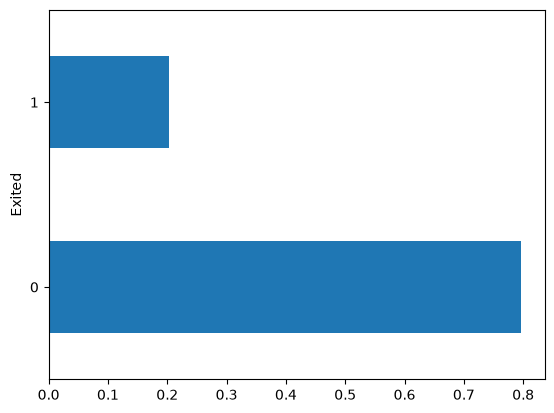

In [173]:
bank_churn['Exited'].value_counts(normalize=True).plot.barh()   # convert into perc normalize=True

<div style='background-color: #684d62; padding: 1px; border-radius: 12px;'>
<h4>2. Explore the categorical variables vs. the target, and look at the percentage of Churners by “Geography” and “Gender”</h4>
</div>

In [174]:
bank_churn.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerId       10000 non-null  int64  
 1   Surname          10000 non-null  str    
 2   CreditScore      10000 non-null  int64  
 3   Geography        10000 non-null  str    
 4   Gender           10000 non-null  str    
 5   Age              10000 non-null  float64
 6   Tenure           10000 non-null  int64  
 7   EstimatedSalary  10000 non-null  float64
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  str    
 11  IsActiveMember   10000 non-null  str    
 12  Exited           10000 non-null  int64  
dtypes: float64(3), int64(5), str(5)
memory usage: 1.2 MB


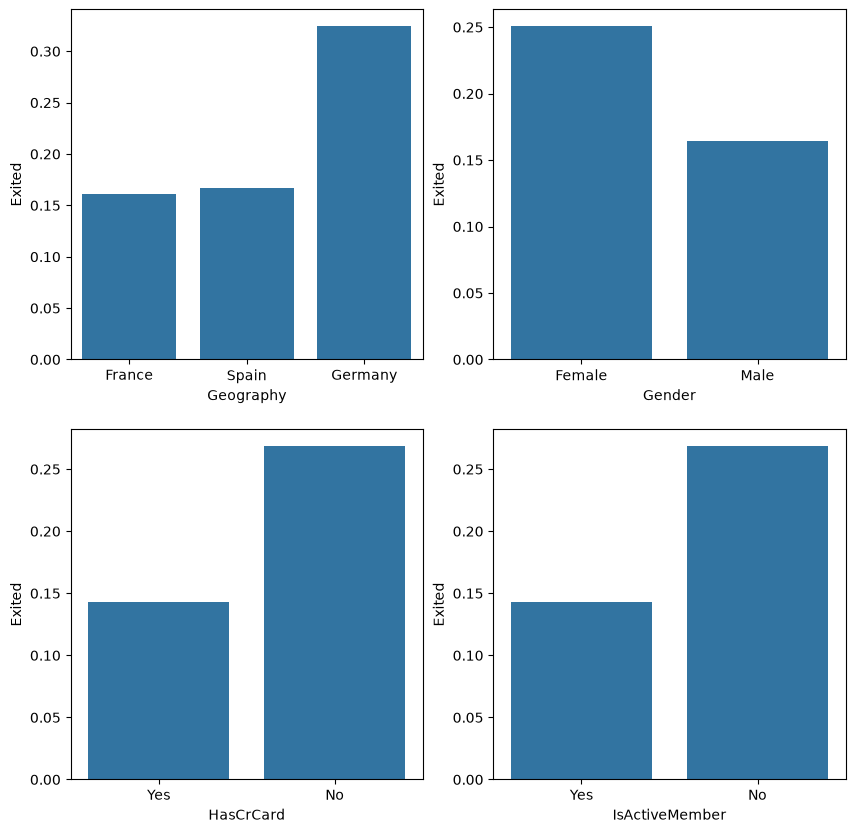

In [175]:
categorical_cols = ['Geography', 'Gender', 'HasCrCard','IsActiveMember']
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for ax, col in zip(axes.flatten(), categorical_cols):
    sns.barplot(
        data=bank_churn,
        x=col,
        y='Exited',
        errorbar=None,
        ax=ax
    )

<div style='background-color: #684d62; padding: 1px; border-radius: 12px;'>
<h4>3. Build box plots for each numeric field, broken out by churners vs. non-churners</h4>
</div>

In [176]:
bank_churn.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerId       10000 non-null  int64  
 1   Surname          10000 non-null  str    
 2   CreditScore      10000 non-null  int64  
 3   Geography        10000 non-null  str    
 4   Gender           10000 non-null  str    
 5   Age              10000 non-null  float64
 6   Tenure           10000 non-null  int64  
 7   EstimatedSalary  10000 non-null  float64
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  str    
 11  IsActiveMember   10000 non-null  str    
 12  Exited           10000 non-null  int64  
dtypes: float64(3), int64(5), str(5)
memory usage: 1.2 MB


In [178]:
numeric_cols = (
    bank_churn
    .select_dtypes(include='number')
    .drop(columns=['CustomerId', 'Exited'])
    .columns
    .tolist()
)
numeric_cols

['CreditScore', 'Age', 'Tenure', 'EstimatedSalary', 'Balance', 'NumOfProducts']

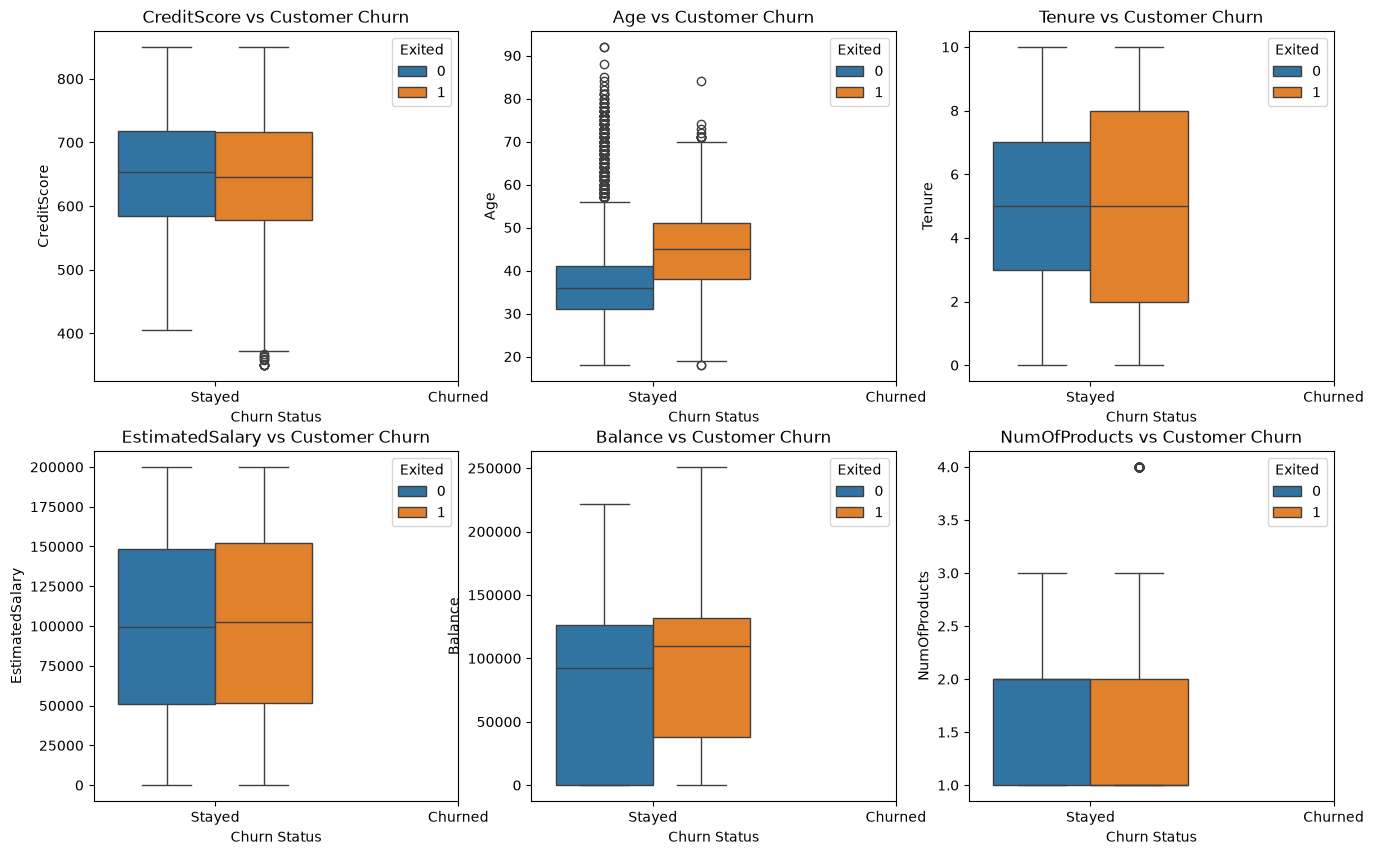

In [179]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, col in zip(axes.flatten(), numeric_cols):

    sns.boxplot(
        data=bank_churn,
        hue='Exited',
        y=col,
        ax=ax
    )

    ax.set_title(f'{col} vs Customer Churn')
    ax.set_xlabel('Churn Status')
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Stayed', 'Churned'])

#plt.tight_layout()

<div style='background-color: #684d62; padding: 1px; border-radius: 12px;'>
<h4>4. Build histograms for each numeric field, broken out by churners vs. non-churners</h4>
</div>

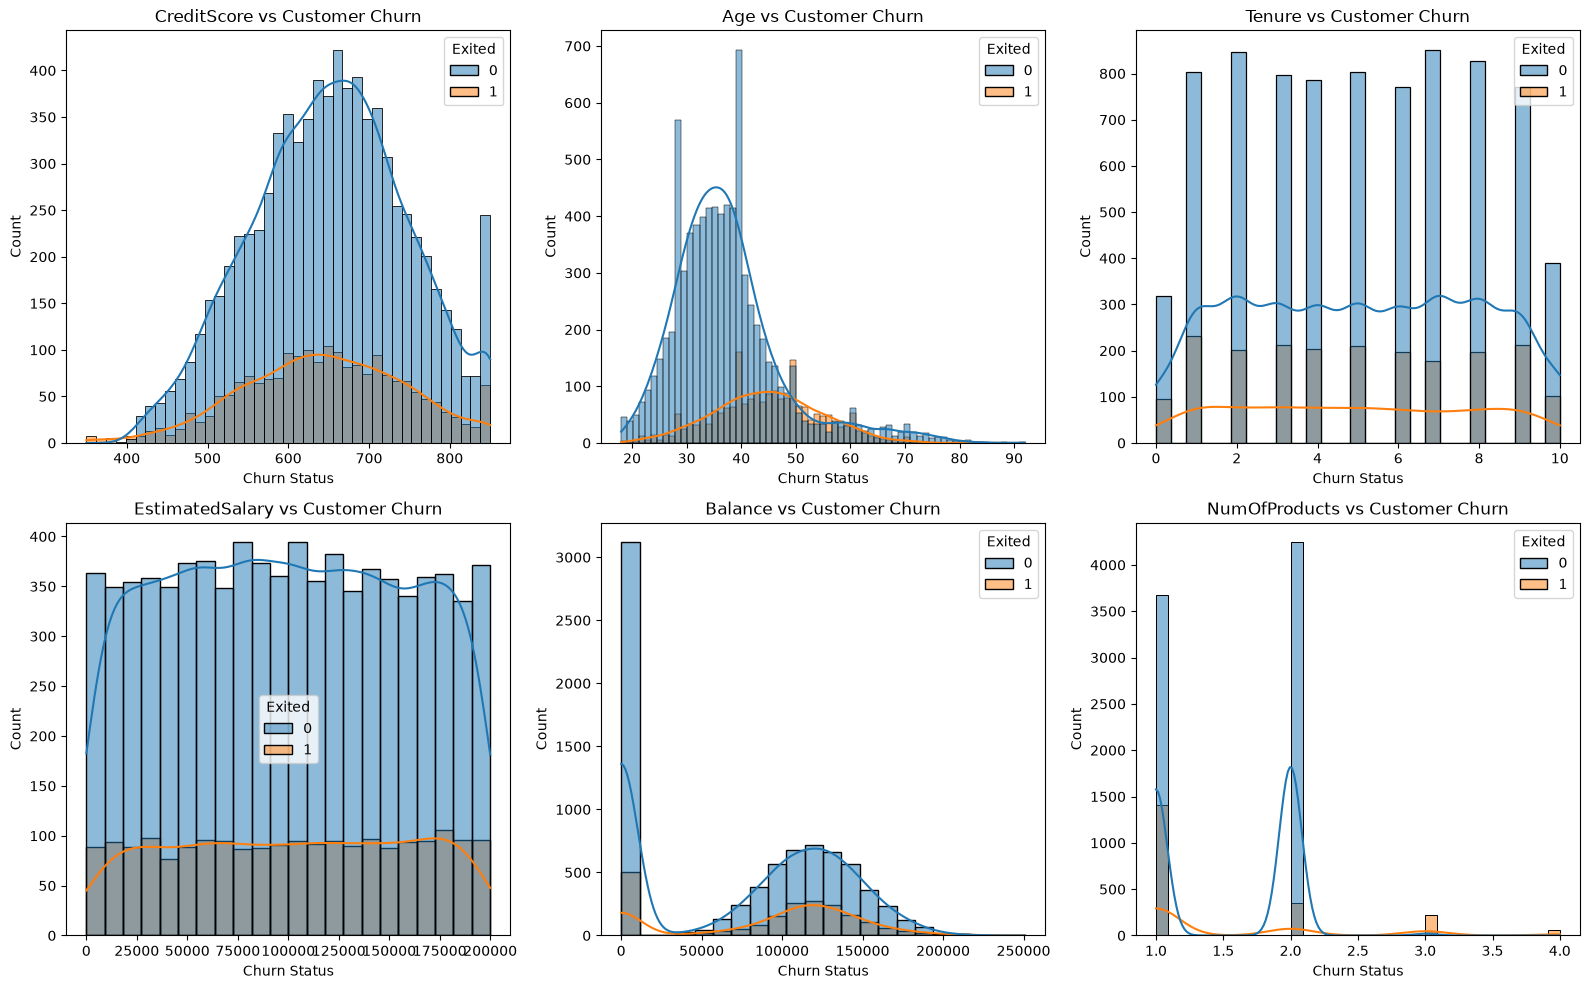

In [180]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, col in zip(axes.flatten(), numeric_cols):

    sns.histplot(
        data=bank_churn,
        x=col,
        hue='Exited',
        kde=True,
        alpha=0.5,
        ax=ax
    )

    ax.set_title(f'{col} vs Customer Churn')
    ax.set_xlabel('Churn Status')
    

plt.tight_layout()

<div style='background-color: #68604d; padding: 1px; border-radius: 12px;'>
<h2>Objective 4</h2>
<h3>Prepare the data for modeling</h3>
Your final objective is to prepare the data for modeling through feature selection, feature engineering, and data splitting.
</div>

In [181]:
bank_churn.head()

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,EstimatedSalary,Balance,NumOfProducts,HasCrCard,IsActiveMember,Exited
0,15634602,Hargrave,619,France,Female,42.0,2,101348.88,0.00,1,Yes,Yes,1
1,15647311,Hill,608,Spain,Female,41.0,1,112542.58,83807.86,1,Yes,Yes,0
2,15619304,Onio,502,France,Female,42.0,8,113931.57,159660.80,3,No,No,1
3,15701354,Boni,699,France,Female,39.0,1,93826.63,0.00,2,No,No,0
4,15737888,Mitchell,850,Spain,Female,43.0,2,79084.10,125510.82,1,Yes,Yes,0


<div style='background-color: #684d62; padding: 1px; border-radius: 12px;'>
<h4>1. Create a new dataset that excludes any columns that aren’t be suitable for modeling</h4>
</div>

In [187]:
modelling_df = bank_churn.drop(['CustomerId', 'Surname'], axis = 1)
modelling_df

,CreditScore,Geography,Gender,Age,Tenure,EstimatedSalary,Balance,NumOfProducts,HasCrCard,IsActiveMember,Exited
0,619,France,Female,42.0,2,101348.88,0.00,1,Yes,Yes,1
1,608,Spain,Female,41.0,1,112542.58,83807.86,1,Yes,Yes,0
2,502,France,Female,42.0,8,113931.57,159660.80,3,No,No,1
3,699,France,Female,39.0,1,93826.63,0.00,2,No,No,0
4,850,Spain,Female,43.0,2,79084.10,125510.82,1,Yes,Yes,0
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,France,Male,39.0,5,96270.64,0.00,2,No,No,0
9996,516,France,Male,35.0,10,101699.77,57369.61,1,Yes,Yes,0
9997,709,France,Female,36.0,7,42085.58,0.00,1,Yes,Yes,1
9998,772,Germany,Male,42.0,3,92888.52,75075.31,2,No,No,1


<div style='background-color: #684d62; padding: 1px; border-radius: 12px;'>
<h4>2. Create dummy variables for categorical fields</h4>
</div>

In [188]:
modelling_df = pd.get_dummies(modelling_df, drop_first=True,) #dtype=int
modelling_df

,CreditScore,Age,Tenure,EstimatedSalary,Balance,NumOfProducts,Exited,Geography_Germany,Geography_Spain,Gender_Male,HasCrCard_Yes,IsActiveMember_Yes
0,619,42.0,2,101348.88,0.00,1,1,False,False,False,True,True
1,608,41.0,1,112542.58,83807.86,1,0,False,True,False,True,True
2,502,42.0,8,113931.57,159660.80,3,1,False,False,False,False,False
3,699,39.0,1,93826.63,0.00,2,0,False,False,False,False,False
4,850,43.0,2,79084.10,125510.82,1,0,False,True,False,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,771,39.0,5,96270.64,0.00,2,0,False,False,True,False,False
9996,516,35.0,10,101699.77,57369.61,1,0,False,False,True,True,True
9997,709,36.0,7,42085.58,0.00,1,1,False,False,False,True,True
9998,772,42.0,3,92888.52,75075.31,2,1,True,False,True,False,False


<div style='background-color: #684d62; padding: 1px; border-radius: 12px;'>
<h4>3. Create a new “balance_v_income” feature, which divides a customer’s bank balance by their estimated salary, then visualize that feature vs. churn status</h4>
</div>

In [190]:
modelling_df['balance_v_income'] = modelling_df['Balance'] / modelling_df['EstimatedSalary']
modelling_df.head()

,CreditScore,Age,Tenure,EstimatedSalary,Balance,NumOfProducts,Exited,Geography_Germany,Geography_Spain,Gender_Male,HasCrCard_Yes,IsActiveMember_Yes,balance_v_income
0,619,42.0,2,101348.88,0.00,1,1,False,False,False,True,True,0.000000
1,608,41.0,1,112542.58,83807.86,1,0,False,True,False,True,True,0.744677
2,502,42.0,8,113931.57,159660.80,3,1,False,False,False,False,False,1.401375
3,699,39.0,1,93826.63,0.00,2,0,False,False,False,False,False,0.000000
4,850,43.0,2,79084.10,125510.82,1,0,False,True,False,True,True,1.587055


<Axes: ylabel='balance_v_income'>

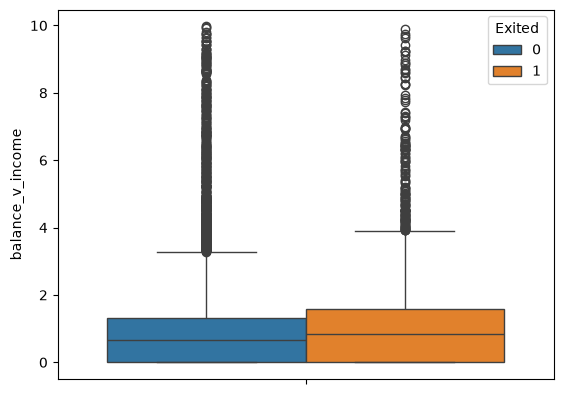

In [194]:
sns.boxplot(data=modelling_df.query('balance_v_income <10'), y='balance_v_income', hue='Exited')

<Axes: ylabel='balance_v_income'>

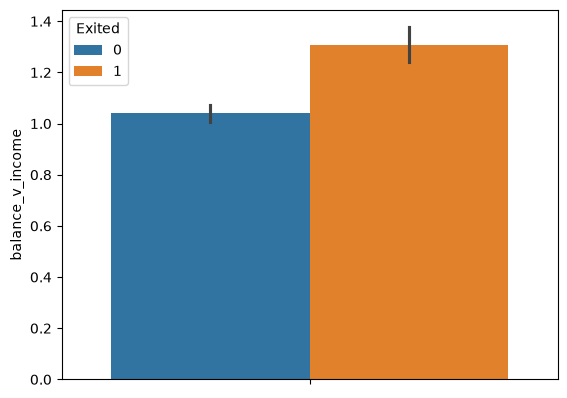

In [195]:
sns.barplot(data=modelling_df.query('balance_v_income <10'), 
            y='balance_v_income', 
            hue='Exited')